# **Machine Learning Foundations**

## **Explicit programming and machine learning**

**Machine learning (ML)** is a field of computer science that uses statistical techniques to let computer systems learn from data without being explicitly programmed. In short: **learning from data**.

**Explicit (traditional) programming** means writing code for each scenario.

| Explicit programming | Machine learning |
| --- | --- |
| We provide the logic; the computer uses it to produce an output. | The algorithm finds a pattern between inputs and outputs; the learned program uses that pattern on new data. |
| Example: a rule that adds two numbers. | Example: learn the addition pattern from examples. |

The examples contrast `2 + 3` with `2 + 3 + 5`. **Technical note:** a regular program can handle any number of inputs if we write it to do so; the contrast is about the rule being supplied by us or learned from examples.

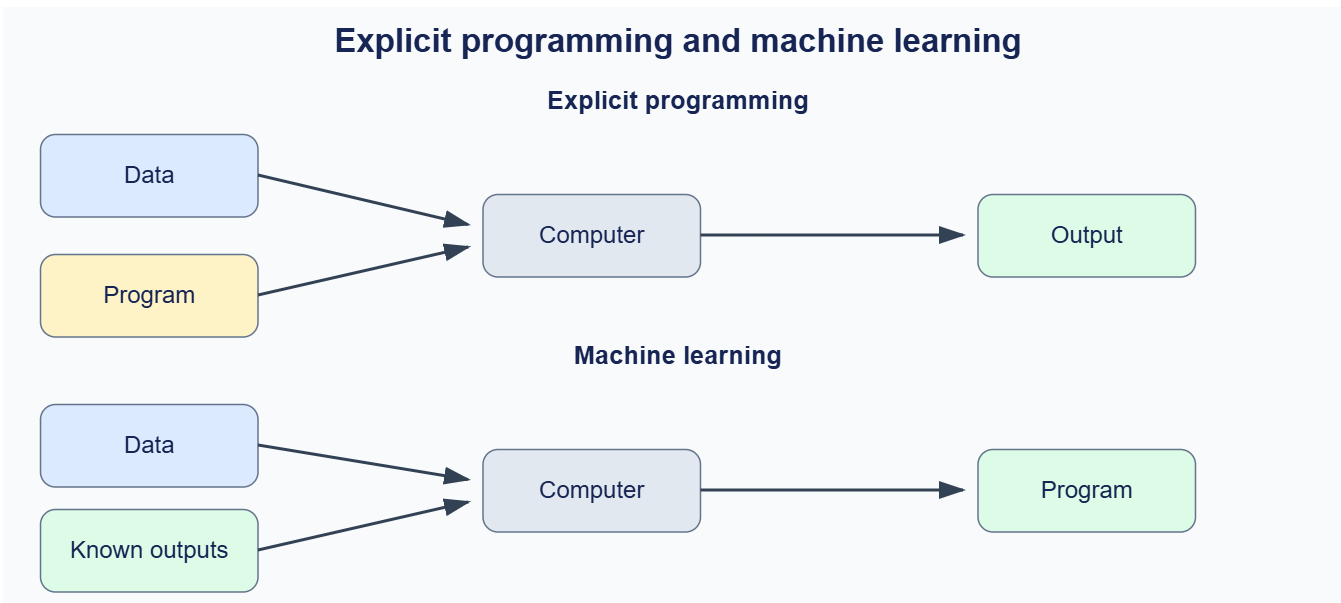

### **When is Machine Learning Useful?**


1\. **Many Scenarios**: ML is useful when a problem has many possible situations, making it difficult to write rules for every case. For example, in spam email filtering, spammers continuously change their wording and techniques to avoid detection. Instead of manually updating rules, an ML model can learn patterns from previous emails and identify new spam messages.

2\. **Too Many Cases:** Some problems involve so many variations that writing rules for each one is practically impossible. For example, in image classification, dogs can have different breeds, sizes, colors, shapes, and appearances. Traditional programming would require numerous rules to recognize these variations, whereas ML can learn relevant features from images and classify them.

3\. **Data Mining:** ML can also be used to discover hidden patterns, relationships, and useful information in large datasets. For example, a supermarket can analyze customers' purchasing habits to identify products that are frequently bought together. These insights can help businesses make better decisions, improve recommendations, and understand customer behavior.

### **History and jobs**

1. **Evolution of Machine Learning**
Machine Learning (ML) is not a new concept; its development began several decades ago, particularly in the 1950s. However, early ML systems were limited because computers had low processing power, memory was expensive, and large datasets were not easily available. As technology advanced, more data became available through the internet, and powerful hardware such as GPUs made it possible to train complex models efficiently. These improvements helped ML become more accurate, practical, and widely used in fields such as healthcare, finance, and education.

2. **Impact of Increasing Professionals on Salaries**
As more people enter a particular field, the supply of skilled professionals increases. If the number of qualified candidates grows faster than the available job opportunities, competition may increase and put downward pressure on salaries, especially for entry-level positions. However, this is not a universal rule. Salaries also depend on factors such as industry demand, experience, specialized skills, and the value a professional brings to an organization.

### **AI, ML, and DL**

**Intelligence** can involve pattern recognition, creativity, imagination, adaptability, and emotional intelligence. **Artificial intelligence (AI)** means putting intelligence into machines. Early symbolic AI used many explicit `if`–`else` rules.

An **expert system** uses a human expert's knowledge. A knowledge engineer puts that knowledge into a knowledge base; an inference engine applies it, and a user interacts through an interface.

nb01_expert_system.svg

## **Limits of expert systems; ML and DL**

**Expert systems** can work on closed, specific problems such as chess. They are difficult to use for fuzzy problems such as recognizing dogs, because it is not practical to write an `if`–`else` rule for every appearance. ML addresses this by learning patterns from data.

**ML** learns patterns from data and generates rules that were not explicitly written. Better data can improve performance, but it does not guarantee better results.

**DL** uses different algorithms inspired by the brain. Neural networks use neurons (including perceptrons), but do not work exactly like a brain. DL can learn features from raw data, which can reduce manual feature creation. **Technical note:** more layers do not always mean better performance.

**Deep learning (DL)** sits inside **ML**, which sits inside **AI**, within the broader idea of **intelligence**:

nb01_ai_ml_dl_hierarchy.svg

## **Data types and supervised learning**

Data can be **numerical** (such as age and weight) or **categorical** (such as gender and nation).

nb01_data_types.svg

**DL** can give good results compared with other **ML** methods, but is not suitable everywhere, especially when large **datasets** are unavailable.

## **Types of ML by supervision**

**1. Supervised ML:** both input and output are present. The algorithm finds a mathematical relationship between them to predict an output for new input. Most ML work uses supervised learning.

Each labeled row pairs an example input with the answer the model should learn to predict.

| IQ | CGPA | Placement |
| ---: | ---: | :---: |
| 87 | 7.1 | Y |
| 111 | 8.9 | Y |
| **Input** | **Input** | **Output** |

nb01_supervised_learning.svg

**Regression** has a numerical output, such as package. **Classification** has a categorical output, such as whether it will rain (yes/no).

A **regression** prediction is a number on the same scale as the target.

The probability estimate is converted into a category such as yes or no.

### **Regression example — package from CGPA**

The project placement data has `cgpa` and `package` columns. A straight-line model is

$$\hat{y} = \theta_0 + \theta_1 x,$$

where $\theta_0$ is the intercept and $\theta_1$ is the slope.

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "init_code").is_dir())
placement = pd.read_csv(root / "init_code/day48-simple-linear-regression/placement.csv")
X_train, X_test, y_train, y_test = train_test_split(
    placement[["cgpa"]], placement["package"], test_size=0.2, random_state=42
)
model = LinearRegression().fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Slope: {model.coef_[0]:.2f}; test MAE: {mean_absolute_error(y_test, predictions):.2f}")


Slope: 0.57; test MAE: 0.23


The MAE is the average absolute prediction error, in the package column's units. The code follows the project's linear-regression example and evaluates on rows not used for fitting.

### **Classification example — will it rain?**

Here, humidity and sunshine are the inputs and rain/no rain is the category. Logistic regression estimates a probability using the sigmoid:

$$\sigma(z) = \frac{1}{1 + e^{-z}}.$$

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Columns: humidity and sunny (1 = yes, 0 = no); labels: rain (1) or no rain (0).
X = np.array([[35,1],[42,1],[50,1],[58,1],[68,1],[75,1],
              [45,0],[55,0],[62,0],[70,0],[78,0],[88,0]])
y = np.array([0,0,0,0,0,0,0,0,0,1,1,1])
rain_model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X, y)
print("Predicted rain probabilities:", rain_model.predict_proba([[84,0],[46,1]])[:, 1].round(2))


Predicted rain probabilities: [0.72 0.03]


These are demonstration data, not a weather forecast. The probabilities show the model's estimates for the two example inputs.

## **Unsupervised ML**

**A dimension is a column.** Unsupervised ML uses input columns without supplied output labels. For example, IQ and CGPA can be used as inputs without a target label. It does not predict a known target; common tasks include:

### **1. Clustering**

Clustering makes groups from similar features. In e-commerce, it can group customers with similar behavior. It can use many dimensions, not only two.

The algorithm finds groups; a person still decides what those groups mean.

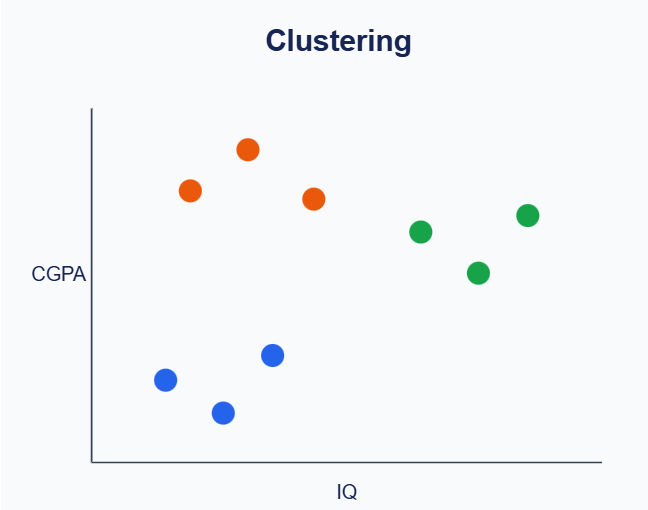

**K-means** is one clustering algorithm. We choose the number of groups, $K$; it assigns points to nearby centers and updates each center.

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

students = pd.read_csv(root / "init_code/kmeans/student_clustering.csv")
features = students[["cgpa", "iq"]]
scaled = StandardScaler().fit_transform(features)
labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(scaled)
print("Students per cluster:", pd.Series(labels).value_counts().sort_index().tolist())


Students per cluster: [50, 50, 50, 50]


Scaling puts CGPA and IQ on comparable ranges before distances are calculated. The counts show how many students were assigned to each of the four clusters; cluster numbers do not have an ordered meaning.

### **2. Dimensionality reduction**

Dimensionality reduction reduces the number of input columns. Some columns may not affect the result and can slow computation. The house example combines rooms and washrooms into square-foot area, calling this feature extraction; PCA can also reduce dimensions. Reduced dimensions can help visualize data that cannot be drawn directly.

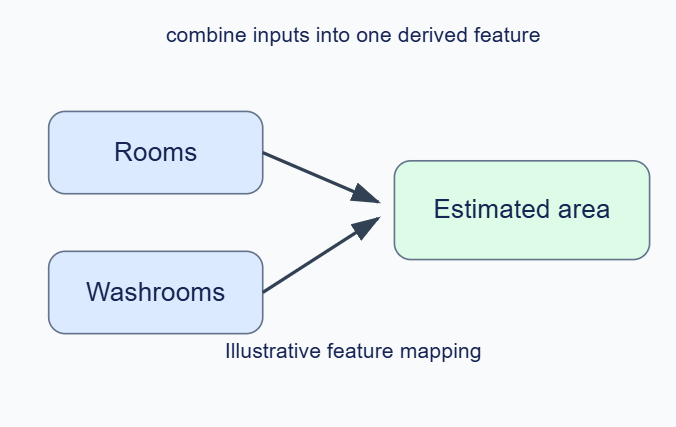

**Technical note:** combining rooms and washrooms into area is feature construction; PCA is a separate method that transforms columns.

### **3. Anomaly detection**

Anomaly detection finds unusual points, for example manufacturing defects, credit-card transactions, or loan applications. The initial suggestion is to detect and remove outliers.

**Technical note:** investigate an anomaly before removing it; it may be an error or an important event.

## **Anomaly detection, association rules, and semi-supervised ML**

Anomalies can appear in a scatter plot or a time series:

nb01_anomaly_patterns.svg

### **4. Association-rule learning**

Association rules discover interesting relationships between variables in a large dataset. They use **if–then** rules: the “if” part is the **antecedent**, and the “then” part is the **consequent**.

An association shows that items occur together; it does not show that one causes the other.

- **Market-basket analysis:** find products often purchased together. One example is beer and diapers in an American store.
- **Recommendation systems:** suggest products based on user behavior.

Algorithms include Apriori and Eclat.

### **3. Semi-supervised ML**

Semi-supervised ML uses labeled and unlabeled data. When labeling a large dataset is expensive, we can label a few examples and use them to help label the rest. For example, naming one person in Google Photos so it can group other pictures of that person.

The labeled examples guide how the unlabeled examples are grouped or classified.

## **Reinforcement learning**

In reinforcement learning, an **agent** learns by interacting with an **environment**. It seeks rewards and avoids penalties. Examples include learning how to behave at college, a self-driving car, and AlphaGo.

Rewards give feedback about how useful an action was in that situation.

**Technical note:** “no data” is a simplification; the agent learns from feedback generated by its interactions.

**First identify which ML category fits the problem: supervised, unsupervised, or another type.**

## **ML training in production**

**Production** is the server where deployed code runs. The path is you → server → IP address → users. The server environment is production; coding on a machine is development.

### **1. Batch learning (offline)**

Train the model on all available data at once, then deploy it to the server. In production, it makes predictions.

nb01_batch_online.svg

## **Batch updates and online learning**

### **Problems with batch learning**

A batch model is static, so it does not automatically handle new data or scenarios, such as new movies in a recommendation system. To update it, bring the model down, combine old and new data, retrain, test, and redeploy. This can happen periodically—for example, daily, weekly, or monthly.

It stays unchanged in production until a retrained version is deployed.

nb01_batch_online.svg

Disadvantages include growing data, hardware limits or lack of instant connectivity, and new data becoming available only after a delay. A delayed news feed and defense systems are examples where delay can matter.

### **2. Online ML (incremental learning)**

Give the model new data in small chunks called **mini-batches**. It updates after each chunk, so it can both predict and learn in production.

**Chatbots such as Siri and Alexa are examples.**

## **Online learning**

A YouTube feed can update based on a click.

nb01_batch_online.svg

Online learning can be useful when the problem changes quickly (**concept drift**), such as in stock markets or e-commerce. Small chunks can also reduce cost and speed up training.

Concept drift means the patterns in incoming data change over time.

In scikit-learn, `SGDRegressor.partial_fit` supports incremental updates. Other streaming tools include River and Vowpal Wabbit.

**Learning rate** is how quickly a model incorporates new information. Training on every instance may cause it to forget older patterns; training too slowly may leave it behind.

## **Out-of-core learning**

When data is too large to load at once, read it in chunks and train or process each chunk.

The chunks let a program process data without holding the entire dataset in memory.

nb01_out_of_core_pipeline.svg

**Technical note:** processing chunks from a file is out-of-core learning; an in-memory chunk example only demonstrates the update pattern.

In [ ]:
from sklearn.linear_model import SGDRegressor

# Incremental updates on small chunks of the project placement data.
online = SGDRegressor(random_state=42, max_iter=1000, tol=1e-3)
for start in range(0, len(placement), 40):
    batch = placement.iloc[start:start + 40]
    online.partial_fit(batch[["cgpa"]], batch["package"])
print("Updated on", (len(placement) + 39) // 40, "chunks; final coefficient:", round(online.coef_[0], 2))


Updated on 5 chunks; final coefficient: 0.42


The coefficient changes as each chunk is processed; one pass is only an illustration, not a tuned model. This in-memory example is not a full out-of-core pipeline.

## **Risks and offline/online comparison**

Out-of-core learning can be confusing because it processes chunks but may still run offline. Choosing chunk sizes and a learning rate takes practice.

It is also risky: incoming data may be wrong or a server may be hacked. Active monitoring and anomaly detection can reject wrong data; if needed, take the server offline and restore its last state.

| Offline learning | Online learning |
| --- | --- |
| Model stays constant between training runs; simpler and uses fewer repeated computations. | Model changes as new data arrives; requires ongoing computation and is harder to manage. |
| Useful when patterns stay constant, such as image classification. Offline tools include scikit-learn, TensorFlow, PyTorch, Keras, and Spark MLlib. | Useful when patterns change in finance, economics, and health. Online tools include MOA, SAMOA, scikit-multiflow, and streamDM. |

## **Instance-based and model-based ML**

Learned parameters can take different forms: neural networks have weights, Naive Bayes has probabilities, and linear regression has a slope and intercept.

The examples contrast two learning approaches:

| Instance-based | Model-based |
| --- | --- |
| Memorizes examples and predicts from similarity or distance to stored examples. | Learns a mathematical function to describe the relationship in data. |

### **Instance-based: K-nearest neighbors (KNN)**

When a new point arrives, KNN compares it with stored points. In this example, the new point is near two “Yes” points and one “No” point, so it predicts “Yes.”

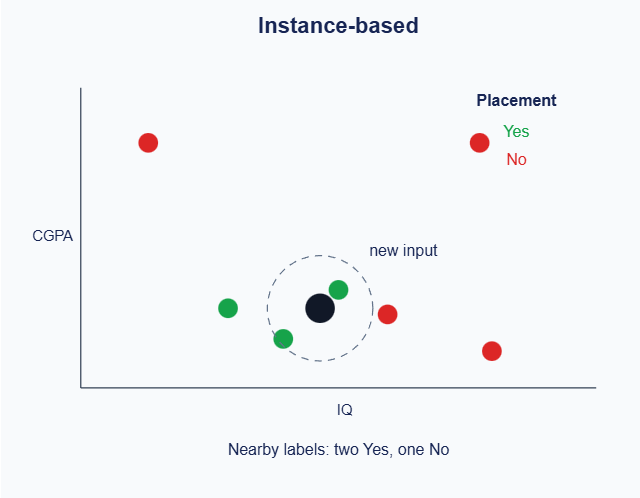

### **Model-based**

A model learns a mathematical function from data. After training, it can use the function without keeping the training points for every prediction. A decision boundary separates “Yes” and “No.”

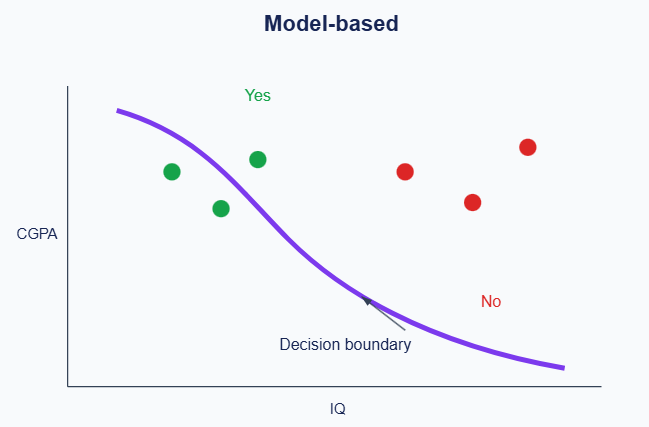

**Technical note:** neither approach guarantees good generalization; that depends on the data and model.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Small CGPA/IQ example following the page 3.3 diagram.
X = [[2.0, 80], [2.5, 90], [2.8, 100], [3.1, 108], [3.2, 110]]
y = ["No", "No", "No", "Yes", "Yes"]
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(X, y)
print("Prediction for new point:", knn.predict([[3.0, 108]])[0])


Prediction for new point: Yes


The prediction is based on the three nearest examples, matching the two-Yes, one-No example. The example is illustrative, not a placement decision rule.